<a href="https://colab.research.google.com/github/vzuza/mapa_restec_ceped/blob/main/mapa_residentes_restec.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [103]:
%pip -q install geopandas contextily matplotlib pandas requests unidecode

In [104]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx
import numpy as np
import re
import requests
import zipfile

from pathlib import Path
from unidecode import unidecode
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "figure.facecolor": "white",
    "savefig.facecolor": "white"
})

PASTA_SAIDA = Path("/content/mapas_restec")
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

CRS_MAPA = "EPSG:3857"

COR_RESIDENTES = "#176B87"
COR_SEM_REGISTRO = "#E8EDF1"
COR_LIMITE = "#FFFFFF"
COR_TEXTO = "#243746"

In [105]:
# ==========================================
# LEITURA DA BASE RESTEC
# ==========================================

ARQUIVO = "/content/Tabela_Municipio_Area_Forca_Residentes.xlsx"

df = pd.read_excel(
    ARQUIVO,
    dtype={
        "MUN": "string",
        "area_atuacao": "string",
        "Forca": "string"
    }
)

# Padronização dos nomes das colunas
df.columns = df.columns.str.strip()

# Verificar estrutura
print("Dimensão da base:", df.shape)
print(df.dtypes)

# Padronização textual
def padronizar_nome(valor):
    if pd.isna(valor):
        return None

    valor = unidecode(str(valor)).upper().strip()
    return re.sub(r"\s+", " ", valor)

df["chave_municipio"] = df["MUN"].map(padronizar_nome)

df["Forca"] = df["Forca"].str.strip()
df["area_atuacao"] = df["area_atuacao"].str.strip()

# Residentes como variável numérica
df["residentes"] = pd.to_numeric(
    df["residentes"],
    errors="coerce"
).fillna(0)

# Remover registros sem identificação
df = df.dropna(
    subset=["chave_municipio", "Forca"]
).copy()

# Conferência
print("\nRegistros:", len(df))
print("Resident es:", df["residentes"].sum())
print("\nForças:")
print(df["Forca"].value_counts())

print("\nÁreas de atuação:")
print(df["area_atuacao"].value_counts())

Dimensão da base: (221, 4)
MUN             string[python]
area_atuacao    string[python]
Forca           string[python]
residentes               int64
dtype: object

Registros: 220
Resident es: 335

Forças:
Forca
Departamento Penitenciário (DEPPEN)    87
Polícia Científica (PCP)               33
Polícia Civil (PCPR)                   31
Polícia Militar (PMPR)                 25
SESP                                   20
Corpo de Bombeiros (CBMPR)             19
UNESPAR                                 5
Name: count, dtype: Int64

Áreas de atuação:
area_atuacao
Direito                                  37
Ciências Humanas ou Sociais Aplicadas    28
Serviço Social                           26
Ciências Humanas ou da Saúde             24
Pedagogia                                22
Ciências da Saúde                        18
Psicologia                               13
Ciências Contábeis                        7
Ciências Biológicas e da Saúde            7
Medicina Veterinária                   

In [106]:
# ==========================================
# AGREGAÇÃO POR MUNICÍPIO
# ==========================================

# Total de residentes por município
residentes_mun = (
    df.groupby("chave_municipio", as_index=False)
      .agg(residentes=("residentes", "sum"))
)

# Total de residentes por município e força
forcas_mun = (
    df.groupby(
        ["chave_municipio", "Forca"],
        as_index=False
    )
    .agg(residentes=("residentes", "sum"))
)

# Total de residentes por município e área
areas_mun = (
    df.groupby(
        ["chave_municipio", "area_atuacao"],
        as_index=False
    )
    .agg(residentes=("residentes", "sum"))
)

print("Total de residentes:", residentes_mun["residentes"].sum())
print("Municípios com residentes:", len(residentes_mun))
print("Quantidade de forças:", df["Forca"].nunique())

display(residentes_mun.sort_values(
    "residentes", ascending=False
).head(10))

Total de residentes: 335
Municípios com residentes: 26
Quantidade de forças: 7


,chave_municipio,residentes
8,CURITIBA,123
14,LONDRINA,28
15,MARINGA,25
4,CASCAVEL,23
20,PONTA GROSSA,22
9,FOZ DO IGUACU,20
11,GUARAPUAVA,17
24,UMUARAMA,13
10,FRANCISCO BELTRAO,13
7,CRUZEIRO DO OESTE,8


In [107]:
# ==========================================
# MALHA MUNICIPAL DO PARANÁ
# ==========================================

PASTA_MALHA = Path("/content/malha_municipal_PR")
PASTA_MALHA.mkdir(parents=True, exist_ok=True)

URL = (
    "https://geoftp.ibge.gov.br/organizacao_do_territorio/"
    "malhas_territoriais/malhas_municipais/"
    "municipio_2022/UFs/PR/PR_Municipios_2022.zip"
)

arquivo_zip = PASTA_MALHA / "PR_Municipios_2022.zip"

if not arquivo_zip.exists():
    resposta = requests.get(URL, timeout=180)
    resposta.raise_for_status()
    arquivo_zip.write_bytes(resposta.content)

with zipfile.ZipFile(arquivo_zip) as arquivo:
    arquivo.extractall(PASTA_MALHA)

shapefile = next(PASTA_MALHA.rglob("*.shp"))

malha = gpd.read_file(shapefile)

malha = malha.rename(columns={
    "NM_MUN": "name_muni",
    "CD_MUN": "codigo_ibge"
})

malha["chave_municipio"] = (
    malha["name_muni"].map(padronizar_nome)
)

print("Municípios:", len(malha))
print("CRS:", malha.crs)

Municípios: 399
CRS: EPSG:4674


In [108]:
# ==========================================
# CRUZAMENTO DA MALHA COM A BASE RESTEC
# ==========================================

mapa_dados = malha.merge(
    residentes_mun,
    on="chave_municipio",
    how="left",
    indicator=True,
    validate="one_to_one"
)

mapa_dados["possui_registro"] = (
    mapa_dados["_merge"].eq("both")
)

mapa_dados["residentes"] = (
    mapa_dados["residentes"].fillna(0)
)

mapa_plot = mapa_dados.to_crs(CRS_MAPA)

print("\nVALIDAÇÃO")
print("Total:", len(mapa_plot))
print("Com registros:", mapa_plot["possui_registro"].sum())
print("Sem registros:", (~mapa_plot["possui_registro"]).sum())
print("Residentes:", mapa_plot["residentes"].sum())


VALIDAÇÃO
Total: 399
Com registros: 26
Sem registros: 373
Residentes: 335.0


In [112]:
# ==========================================
# 7. PADRÃO VISUAL E ELEMENTOS CARTOGRÁFICOS
# ==========================================

from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib import patheffects
from matplotlib.ticker import FuncFormatter

# Paleta institucional
AZUL = "#14566B"
AZUL_CLARO = "#75AFC0"
CINZA = "#AEBBC4"
TEXTO = "#263746"
BRANCO = "#FFFFFF"

# Extensão comum para todos os mapas
xmin, ymin, xmax, ymax = mapa_plot.total_bounds

dx = xmax - xmin
dy = ymax - ymin

LIMITES = (
    xmin - dx * 0.05,
    xmax + dx * 0.05,
    ymin - dy * 0.05,
    ymax + dy * 0.05
)

# Latitude média para correção da escala no Web Mercator
mapa_geo = mapa_plot.to_crs("EPSG:4326")
latitude_media = mapa_geo.geometry.union_all().centroid.y

def adicionar_basemap(ax):
    """
    Adiciona o mapa-base antes das camadas vetoriais.
    """

    ax.set_xlim(LIMITES[0], LIMITES[1])
    ax.set_ylim(LIMITES[2], LIMITES[3])

    try:
        ctx.add_basemap(
            ax,
            source=ctx.providers.CartoDB.Positron,
            crs=mapa_plot.crs,
            zoom=7,
            zorder=0,
            reset_extent=False,
            attribution=True
        )
        return True

    except Exception as erro:
        print("Não foi possível carregar o mapa-base:", erro)
        return False


def adicionar_limites(ax, dados, coluna_status=True):
    """
    Desenha municípios com preenchimento translúcido,
    permitindo visualizar o mapa-base.
    """

    sem = dados[~dados["possui_registro"]]
    com = dados[dados["possui_registro"]]

    if not sem.empty:
        sem.plot(
            ax=ax,
            facecolor="#AEBBC4",
            edgecolor="#FFFFFF",
            linewidth=0.35,
            alpha=0.24,
            zorder=2
        )

    if not com.empty:
        com.plot(
            ax=ax,
            facecolor="#27869A",
            edgecolor="#FFFFFF",
            linewidth=0.45,
            alpha=0.20,
            zorder=3
        )


def tamanho_simbolo(valor, maximo, area_maxima=1100):
    """
    Área do círculo diretamente proporcional ao valor.
    """
    if maximo <= 0:
        return 0

    return area_maxima * valor / maximo


def formatar_valor(valor):
    return f"{valor:,.0f}".replace(",", ".")


def valores_referencia(valores, quantidade=3):
    """
    Seleciona valores reais da base para a legenda.
    """
    valores = np.sort(
        pd.Series(valores).dropna().unique()
    )
    valores = valores[valores > 0]

    if len(valores) == 0:
        return []

    indices = np.linspace(
        0, len(valores) - 1,
        min(quantidade, len(valores))
    ).round().astype(int)

    return sorted(set(valores[indices].tolist()))


def adicionar_legenda_proporcional(
    ax, valores, maximo, titulo="Residentes"
):
    """
    Legenda com círculos proporcionais e valores absolutos.
    """

    referencias = valores_referencia(valores)

    if not referencias:
        return

    elementos = []

    for valor in referencias:
        elementos.append(
            ax.scatter(
                [], [],
                s=tamanho_simbolo(valor, maximo),
                facecolor=AZUL,
                edgecolor="white",
                linewidth=0.8,
                label=formatar_valor(valor)
            )
        )

    legenda = ax.legend(
        handles=elementos,
        title=titulo,
        loc="lower right",
        frameon=True,
        scatterpoints=1,
        labelspacing=1.5,
        borderpad=1.2,
        fontsize=8,
        title_fontsize=9,
        facecolor="white",
        edgecolor="#D7DEE3",
        framealpha=0.97
    )

    ax.add_artist(legenda)


def adicionar_elementos(ax):
    """
    Norte, escala gráfica e identificação.
    """

    # Norte
    ax.annotate(
        "N",
        xy=(0.95, 0.94),
        xytext=(0.95, 0.86),
        xycoords="axes fraction",
        textcoords="axes fraction",
        ha="center",
        fontsize=10,
        fontweight="bold",
        color=TEXTO,
        arrowprops=dict(
            arrowstyle="-|>",
            color=TEXTO,
            lw=1.4
        ),
        zorder=20
    )

    # Escala gráfica: 100 km no terreno
    distancia = 100_000 / np.cos(
        np.radians(latitude_media)
    )

    largura = LIMITES[1] - LIMITES[0]
    altura = LIMITES[3] - LIMITES[2]

    x0 = LIMITES[0] + largura * 0.055
    y0 = LIMITES[2] + altura * 0.055

    ax.plot(
        [x0, x0 + distancia],
        [y0, y0],
        color=TEXTO,
        linewidth=3,
        solid_capstyle="butt",
        zorder=20
    )

    ax.plot(
        [x0, x0],
        [y0 - altura * 0.004, y0 + altura * 0.004],
        color=TEXTO,
        linewidth=1,
        zorder=20
    )

    ax.plot(
        [x0 + distancia, x0 + distancia],
        [y0 - altura * 0.004, y0 + altura * 0.004],
        color=TEXTO,
        linewidth=1,
        zorder=20
    )

    ax.text(
        x0 + distancia / 2,
        y0 + altura * 0.012,
        "100 km",
        ha="center",
        fontsize=7,
        color=TEXTO,
        zorder=20
    )

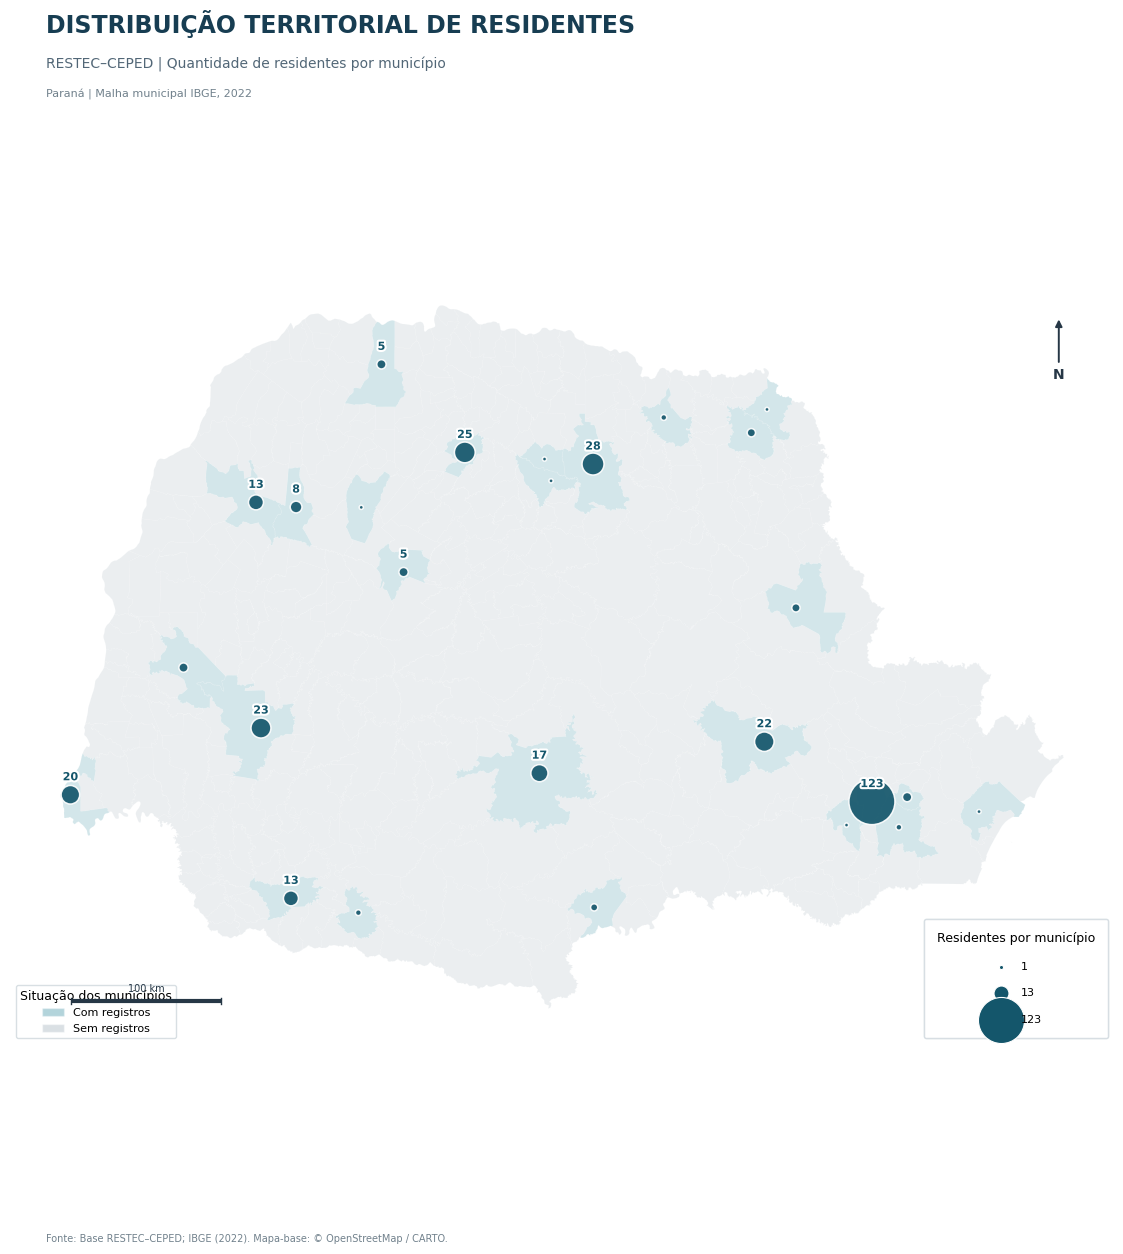

In [114]:
# ==========================================
# 8. MAPA DE RESIDENTES
# ==========================================

fig, ax = plt.subplots(figsize=(12, 13))

fig.subplots_adjust(
    left=0.04,
    right=0.96,
    top=0.88,
    bottom=0.07
)

# 1. Mapa-base: sempre primeiro
def adicionar_basemap(ax):
    try:
        ctx.add_basemap(
            ax,
            source=ctx.providers.OpenStreetMap.Mapnik,
            crs=mapa_plot.crs,
            zoom=7,
            attribution=False
        )
    except Exception as erro:
        print(f"Não foi possível carregar o mapa-base: {erro}")

# 2. Limites municipais translúcidos
adicionar_limites(ax, mapa_plot)

# 3. Municípios com residentes
dados = mapa_plot[
    mapa_plot["residentes"] > 0
].copy()

dados["ponto"] = dados.geometry.representative_point()

maximo = dados["residentes"].max()

tamanhos = [
    tamanho_simbolo(v, maximo)
    for v in dados["residentes"]
]

# 4. Símbolos proporcionais
ax.scatter(
    dados["ponto"].x,
    dados["ponto"].y,
    s=tamanhos,
    color=AZUL,
    edgecolor="white",
    linewidth=1.1,
    alpha=0.92,
    zorder=6
)

# 5. Rótulos dos principais municípios
principais = dados.nlargest(12, "residentes")

for _, linha in principais.iterrows():

    ponto = linha["ponto"]

    rotulo = ax.annotate(
        formatar_valor(linha["residentes"]),
        (ponto.x, ponto.y),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=8,
        fontweight="bold",
        color=AZUL,
        zorder=10
    )

    rotulo.set_path_effects([
        patheffects.withStroke(
            linewidth=3,
            foreground="white"
        )
    ])

# 6. Legenda de municípios
legenda_status = [
    Patch(
        facecolor="#27869A",
        alpha=0.35,
        edgecolor="white",
        label="Com registros"
    ),
    Patch(
        facecolor="#AEBBC4",
        alpha=0.45,
        edgecolor="white",
        label="Sem registros"
    )
]

leg1 = ax.legend(
    handles=legenda_status,
    title="Situação dos municípios",
    loc="lower left",
    frameon=True,
    fontsize=8,
    title_fontsize=9,
    facecolor="white",
    edgecolor="#D7DEE3",
    framealpha=0.97
)

ax.add_artist(leg1)

# 7. Legenda quantitativa dos círculos
adicionar_legenda_proporcional(
    ax,
    dados["residentes"],
    maximo,
    titulo="Residentes por município"
)

# 8. Elementos cartográficos
adicionar_elementos(ax)

# 9. Títulos
fig.text(
    0.07, 0.955,
    "DISTRIBUIÇÃO TERRITORIAL DE RESIDENTES",
    fontsize=17,
    fontweight="bold",
    color="#173D52"
)

fig.text(
    0.07, 0.928,
    "RESTEC–CEPED | Quantidade de residentes por município",
    fontsize=10,
    color="#526777"
)

fig.text(
    0.07, 0.905,
    "Paraná | Malha municipal IBGE, 2022",
    fontsize=8,
    color="#71818C"
)

# 10. Rodapé
fig.text(
    0.07, 0.025,
    "Fonte: Base RESTEC–CEPED; IBGE (2022). "
    "Mapa-base: © OpenStreetMap / CARTO.",
    fontsize=7,
    color="#71818C"
)

ax.set_axis_off()

# Exportação
fig.savefig(
    PASTA_SAIDA / "01_residentes_profissional.png",
    dpi=350,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

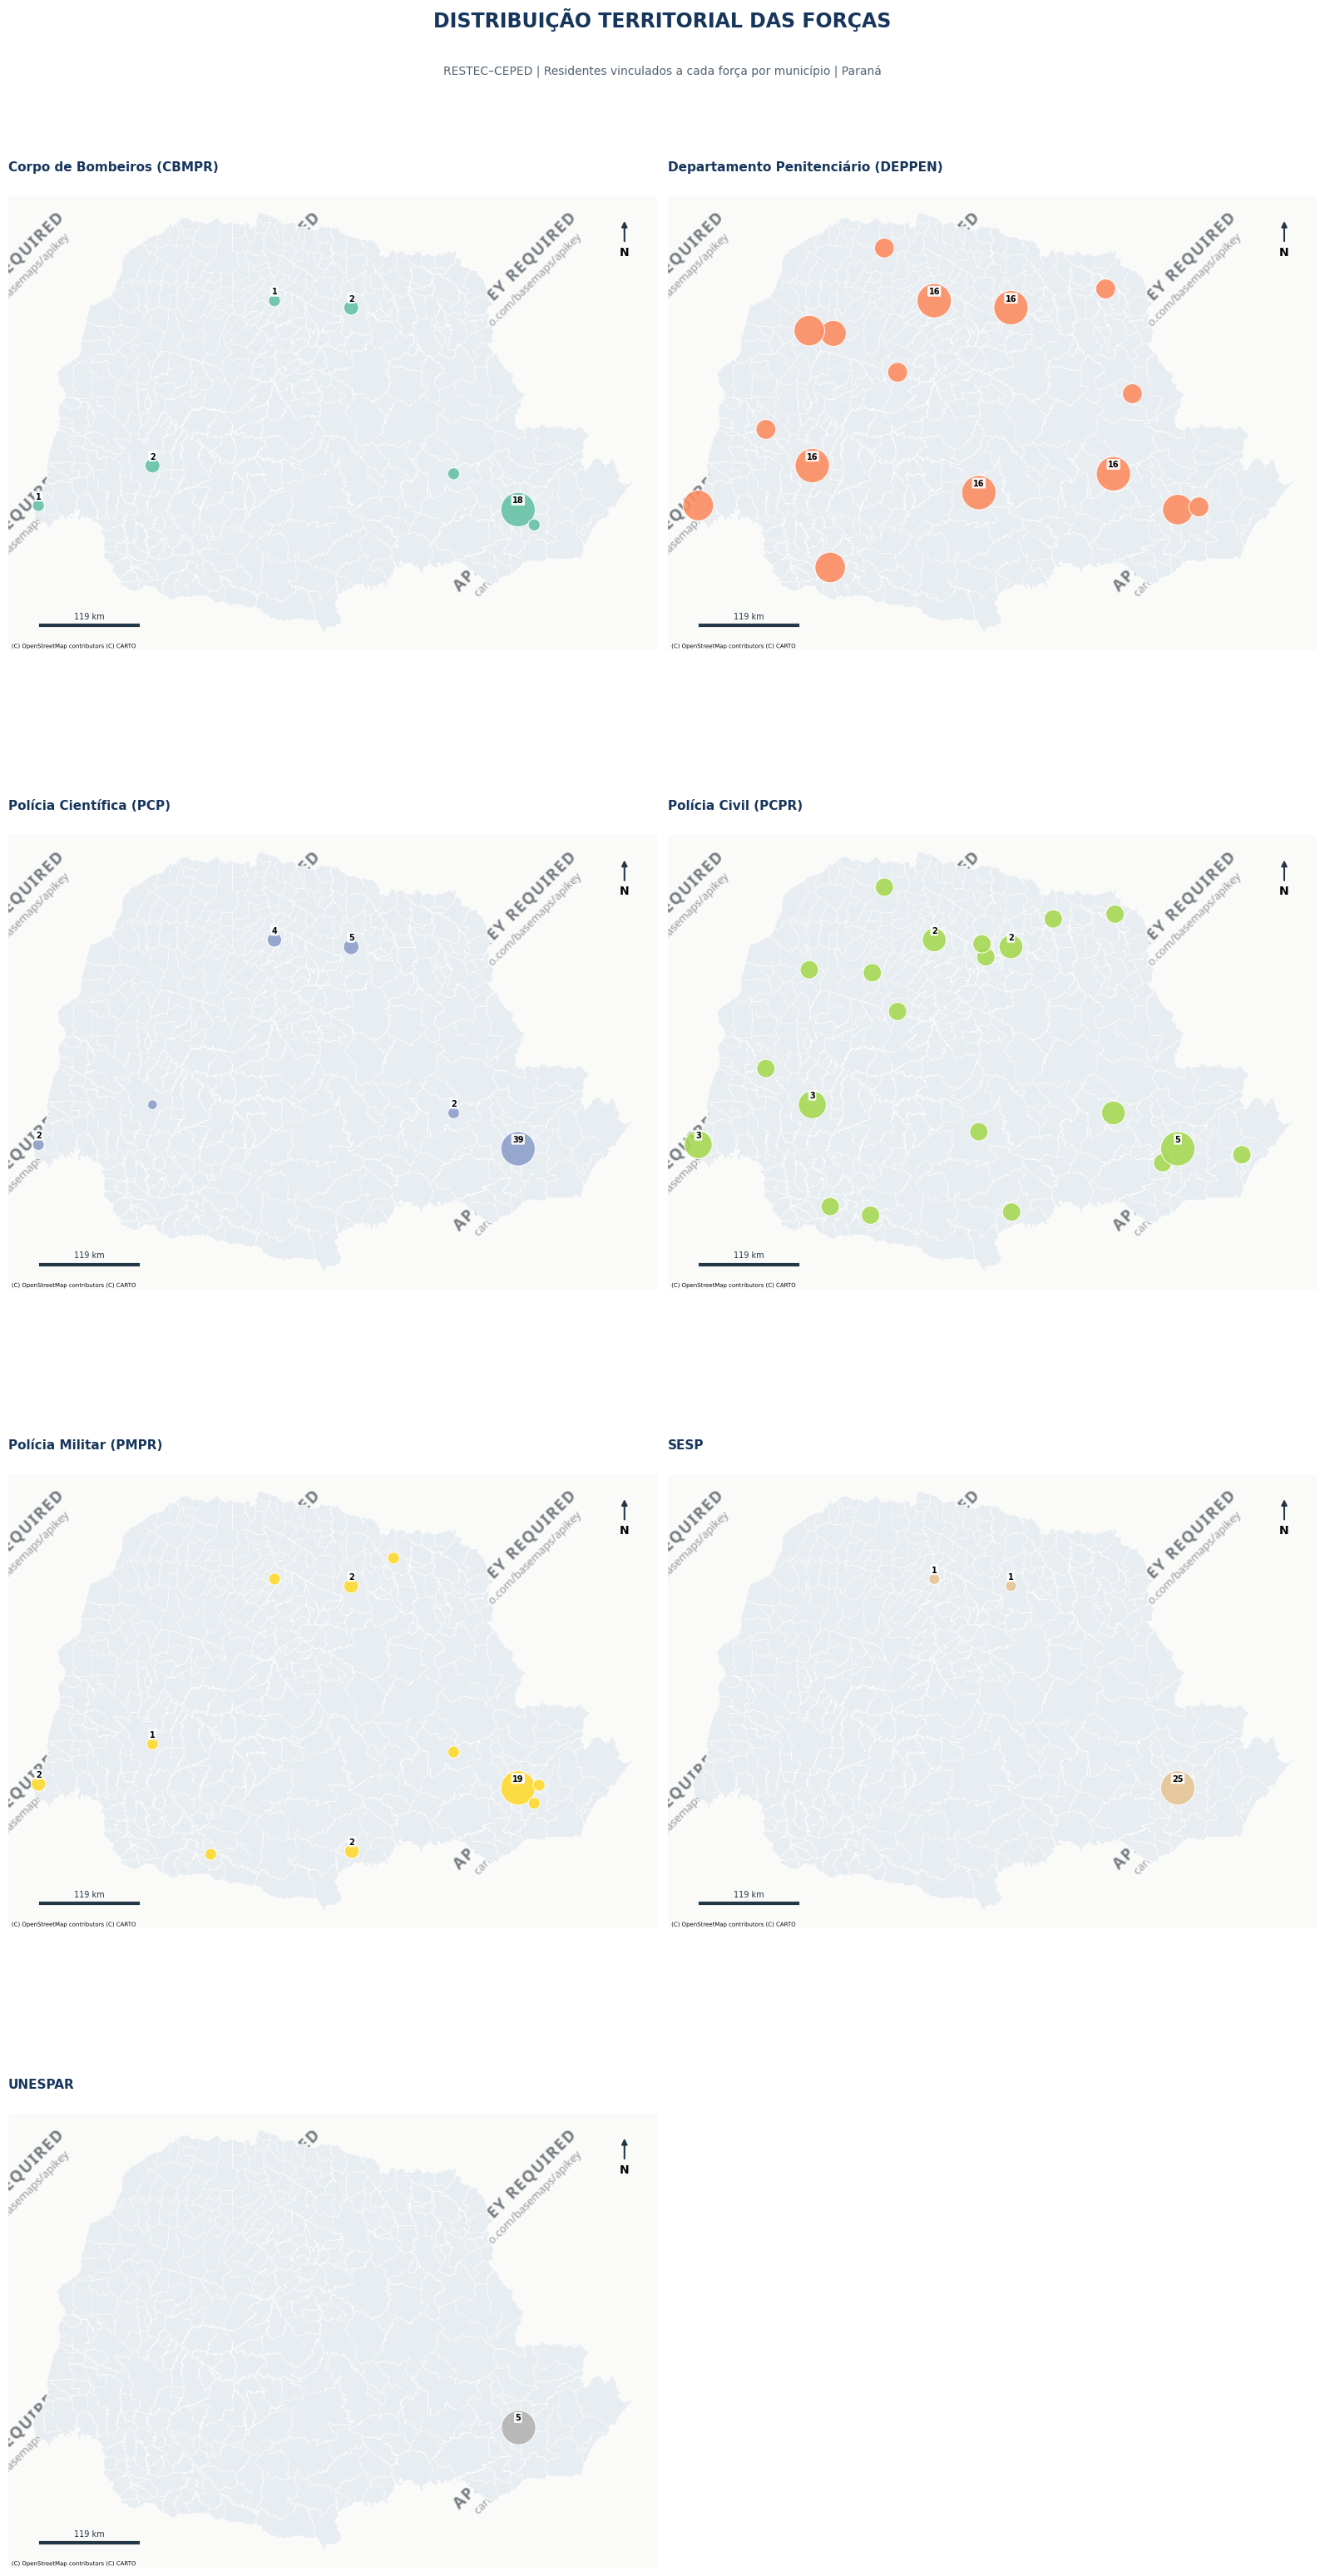

In [111]:
# ==========================================
# MAPAS DE FORÇAS
# ==========================================

forcas = sorted(df["Forca"].dropna().unique())

n = len(forcas)

n_colunas = 2
n_linhas = int(np.ceil(n / n_colunas))

fig, axes = plt.subplots(
    n_linhas,
    n_colunas,
    figsize=(16, 8 * n_linhas)
)

axes = np.atleast_1d(axes).flatten()

cores = plt.cm.Set2(
    np.linspace(0, 1, max(n, 1))
)

for i, forca in enumerate(forcas):

    ax = axes[i]

    # Base territorial
    mapa_plot.plot(
        ax=ax,
        color=COR_SEM_REGISTRO,
        edgecolor="white",
        linewidth=0.35,
        zorder=2
    )

    # Dados específicos da força
    dados_forca = forcas_mun[
        forcas_mun["Forca"] == forca
    ].copy()

    dados_forca = mapa_plot[
        ["chave_municipio", "geometry"]
    ].merge(
        dados_forca,
        on="chave_municipio",
        how="inner"
    )

    dados_forca = dados_forca[
        dados_forca["residentes"] > 0
    ].copy()

    if not dados_forca.empty:

        dados_forca["ponto"] = (
            dados_forca.geometry.representative_point()
        )

        valores = dados_forca["residentes"]

        tamanhos = 35 + 850 * (
            valores / valores.max()
        ) ** 0.85

        ax.scatter(
            dados_forca["ponto"].x,
            dados_forca["ponto"].y,
            s=tamanhos,
            color=cores[i],
            edgecolor="white",
            linewidth=0.8,
            alpha=0.9,
            zorder=5
        )

        # Rótulos dos cinco principais municípios
        principais = dados_forca.nlargest(
            5, "residentes"
        )

        for _, linha in principais.iterrows():

            ax.annotate(
                formatar_valor(linha["residentes"]),
                (linha["ponto"].x, linha["ponto"].y),
                xytext=(0, 6),
                textcoords="offset points",
                ha="center",
                fontsize=7,
                fontweight="bold",
                bbox=dict(
                    boxstyle="round,pad=0.15",
                    fc="white",
                    ec="none",
                    alpha=0.9
                ),
                zorder=7
            )

    adicionar_basemap(ax)

    ax.set_xlim(limites[0], limites[1])
    ax.set_ylim(limites[2], limites[3])

    ax.set_title(
        forca,
        loc="left",
        fontsize=11,
        color="#17365D",
        pad=12
    )

    adicionar_elementos(
        ax,
        limites[0], limites[1],
        limites[2], limites[3]
    )

    ax.set_axis_off()

# Remover painéis vazios
for j in range(n, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(
    "DISTRIBUIÇÃO TERRITORIAL DAS FORÇAS",
    fontsize=17,
    fontweight="bold",
    color="#17365D",
    y=1.01
)

fig.text(
    0.5, 0.985,
    "RESTEC–CEPED | Residentes vinculados a cada força por município | Paraná",
    ha="center",
    fontsize=10,
    color="#526170"
)

plt.tight_layout()

plt.savefig(
    PASTA_SAIDA / "02_mapas_forcas.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()